# Joint language-model preference fine-tuning — attempt 002

Attempt 001 scored **1.00897** on Kaggle. This attempt tests whether adapting a
pretrained language model to read the question and both responses jointly improves
preference prediction. Lower multiclass log loss is better.

Qwen3 is the general language-model checkpoint family; it is distinct from attempt 001's
frozen embedding model. NF4 QLoRA updates attention adapters and a three-class head.
The training notebook runs on two Kaggle T4 GPUs. Source and aggregate results are
stored here; model weights and data remain outside GitHub.

Development chooses checkpoints and temperature. Confirmation is withheld until
choices are frozen. Previous project results have been examined, so the new split
is not an entirely unseen project-wide test. See [protocol](../docs/ATTEMPT_002.md).


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
candidates=[Path.cwd(),Path.cwd().parent,Path.home()/'prj/llm_classification_finetuning']
REPO=next(p for p in candidates if (p/'results/attempt_002').is_dir())
RESULTS=REPO/'results/attempt_002'
split=json.loads((RESULTS/'split_summary.json').read_text())
baseline=json.loads((RESULTS/'baselines.json').read_text())
index=json.loads((RESULTS/'run_index.json').read_text())
display(pd.Series(split['split_counts'],name='Rows'))
print('Fixed split digest:',split['split_ids_sha256'])
print('Collected UTC:',index['collected_utc'])
if (RESULTS/'pipeline_state.json').exists():
    display(pd.Series(json.loads((RESULTS/'pipeline_state.json').read_text()),name='Workflow state'))


train           45985
dev              5746
confirmation     5746
Name: Rows, dtype: int64

Fixed split digest: 066f7ab82a3f14464ce0ef67bfd8b8b34ed190679bfea5c1fea80abc3aa4ecd1
Collected UTC: 2026-11-01T15:35:10.583180+00:00


stage                         waiting_for_kernel
utc             2026-11-01T15:34:46.176406+00:00
pid                                      3923947
training_job                          qwen4b1024
job                                   qwen4b1024
status                                   RUNNING
Name: Workflow state, dtype: object

## Baselines on the new development split

The majority baseline always predicts A. Its hard one-hot predictions have poor
log loss; the training-prior baseline instead returns three class frequencies.
These baselines use all 5,746 development examples. Tiny pilot subsets are not
directly comparable to this table.


In [2]:
rows={name:baseline[name] for name in ['majority_development','prior_development','structural_gbdt_development']}
display(pd.DataFrame(rows).T.round(5))


,log_loss,accuracy,balanced_accuracy,macro_f1,brier
majority_development,23.46037,0.34911,0.33333,0.17251,1.30178
prior_development,1.09722,0.34911,0.33333,0.17251,0.66575
structural_gbdt_development,1.03375,0.47355,0.46792,0.46359,0.62069


## GPU pilots and completed training runs

Pilots measure memory, speed, numerical stability and artifact persistence. Their
development scores use only 128 examples and are not final quality estimates.
The first pilot exposed incorrect loss scaling with gradient accumulation and DDP;
the corrected trainer computes mean example cross entropy explicitly. A regression
test checks that accumulated and full-batch parameter updates agree.


In [3]:
runs=[]
for entry in index['jobs']:
    path=RESULTS/entry['job']/'summary.json'
    if path.exists():
        s=json.loads(path.read_text())
        runs.append((entry['job'],s))
display(pd.DataFrame([{'job':j,'model':s['model_id'],'pilot':s['pilot'],'steps':s['global_steps'],
    'batch_per_gpu':s['config']['train_batch_size'],'accumulation':s['config']['gradient_accumulation_steps'],
    'seconds_per_step':s['seconds_per_optimizer_step'],'peak_GPU_GB':s['peak_gpu_bytes']/1e9,
    'epochs_completed':s.get('epochs_completed'),'budget_stopped':s.get('stopped_for_budget'),
    'dev_rows':s['final_dev_rows'],'dev_log_loss':s['development']['log_loss'],
    'calibrated_dev_log_loss':s['calibrated_development']['log_loss']}
    for j,s in runs]).round(5))
display(pd.DataFrame([{'job':e['job'],'status':e.get('status',{}).get('status','not recorded'),
    'notebook':e.get('push',{}).get('url','')} for e in index['jobs']]))


,job,model,pilot,steps,batch_per_gpu,accumulation,seconds_per_step,peak_GPU_GB,epochs_completed,budget_stopped,dev_rows,dev_log_loss,calibrated_dev_log_loss
0,pilot1024,Qwen/Qwen3-8B,True,20,1,16,45.64298,7.68065,NaN,None,128,1.12932,1.09465
1,pilot1024_batch4,Qwen/Qwen3-8B,True,10,4,4,57.64078,10.60727,0.15625,False,128,1.12051,1.09794


,job,status,notebook
0,gpu_probe,KernelWorkerStatus.COMPLETE,https://www.kaggle.com/code/arseniytrushin/llm...
1,pilot1024,KernelWorkerStatus.COMPLETE,https://www.kaggle.com/code/arseniytrushin/llm...
2,pilot1024_batch4,KernelWorkerStatus.COMPLETE,https://www.kaggle.com/code/arseniytrushin/llm...
3,qwen4b1024,KernelWorkerStatus.RUNNING,https://www.kaggle.com/code/arseniytrushin/llm...


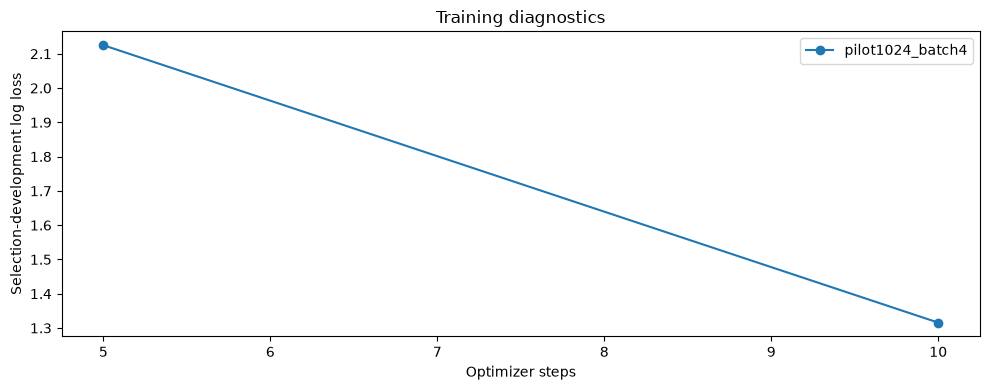

In [4]:
curves=[]
for job,s in runs:
    path=RESULTS/job/'training_progress.jsonl'
    if path.exists():
        progress=pd.read_json(path,lines=True)
        if 'eval_log_loss' in progress:
            curve=progress.dropna(subset=['eval_log_loss'])
            if len(curve):curves.append((job,curve))
if curves:
    fig,ax=plt.subplots(figsize=(10,4))
    for job,curve in curves:ax.plot(curve.step,curve.eval_log_loss,marker='o',label=job)
    ax.set(xlabel='Optimizer steps',ylabel='Selection-development log loss',title='Training diagnostics')
    ax.legend();fig.tight_layout();plt.show()


## Live training statistics

The Kaggle SDK provides a live log streaming endpoint. These snapshots show
optimizer progress and development checkpoints before the full run finishes.
Training loss is noisy across batches. Selection metrics use one orientation and
no temperature calibration; final development/confirmation uses both orientations.


qwen4b1024 snapshot UTC: 2026-11-01T15:34:30.380468+00:00


step                        400.000000
elapsed_seconds            9899.608539
eval_loss                     1.115365
eval_log_loss                 1.115365
eval_accuracy                 0.412109
eval_balanced_accuracy        0.427106
eval_macro_f1                 0.383986
eval_brier                    0.676273
eval_runtime                334.646900
eval_samples_per_second       3.060000
eval_steps_per_second         0.382000
epoch                         0.278309
Name: Latest progress, dtype: float64

,step,elapsed_seconds,eval_loss,eval_log_loss,eval_accuracy,eval_balanced_accuracy,eval_macro_f1,eval_brier,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch
0,200,4974.44678,1.14052,1.14052,0.43848,0.42671,0.36973,0.67338,335.3914,3.053,0.382,0.13915
1,400,9899.60854,1.11537,1.11537,0.41211,0.42711,0.38399,0.67627,334.6469,3.060,0.382,0.27831


Training-prior log loss on the SAME selection subset: 1.0970928520442769


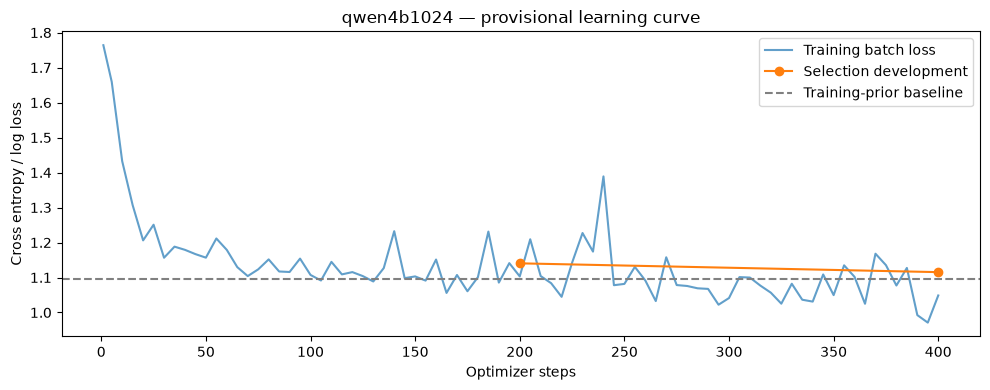

In [5]:
for entry in index['jobs']:
    live_path=RESULTS/entry['job']/'training_live.json'
    if not live_path.exists():continue
    live=json.loads(live_path.read_text())
    print(entry['job'],'snapshot UTC:',live['snapshot_utc'])
    display(pd.Series(live['latest'],name='Latest progress'))
    display(pd.DataFrame(live['validation']).round(5))
    if 'selection_prior_log_loss' in live:
        print('Training-prior log loss on the SAME selection subset:',live['selection_prior_log_loss'])
    progress=pd.read_json(RESULTS/entry['job']/'training_live_progress.jsonl',lines=True)
    fig,ax=plt.subplots(figsize=(10,4))
    training=progress.dropna(subset=['loss'])
    ax.plot(training.step,training.loss,label='Training batch loss',alpha=.7)
    if 'eval_log_loss' in progress:
        val=progress.dropna(subset=['eval_log_loss'])
        ax.plot(val.step,val.eval_log_loss,marker='o',label='Selection development')
    if 'selection_prior_log_loss' in live:
        ax.axhline(live['selection_prior_log_loss'],ls='--',color='gray',label='Training-prior baseline')
    ax.set(xlabel='Optimizer steps',ylabel='Cross entropy / log loss',title=entry['job']+' — provisional learning curve')
    ax.legend();fig.tight_layout();plt.show()


## Frozen model and independent confirmation

Only a non-pilot run can be frozen. The adapter checksum, preprocessing, split IDs,
temperature and notebook version are recorded before confirmation. The competition
inference notebook restores package wheels and weights locally with internet disabled.
An official score is reported only after Kaggle finishes hidden-test evaluation.


In [6]:
selection=RESULTS/'model_selection.json'
if selection.exists():display(pd.Series(json.loads(selection.read_text())))
else:print('No final model has been frozen yet.')
for entry in index['jobs']:
    for name in ['confirmation.json','prediction_summary.json','submission.json']:
        path=RESULTS/entry['job']/name
        if path.exists():
            print(entry['job'],name);display(json.loads(path.read_text()))
    scores=RESULTS/entry['job']/'submissions.json'
    if scores.exists():display(pd.DataFrame(json.loads(scores.read_text())))


No final model has been frozen yet.
